# Phase 2 climat — Analyse approfondie

Notebook complémentaire à `visualize_phase2.ipynb`. Deux axes :

1. **Profondeur agronomique** : croiser les features météo avec les bioagresseurs observés
2. **Corrélations entre features** : identifier les redondances et la structure interne du vecteur météo

## Sections

1. Setup et chargement
2. **Boxplots features × top bioagresseurs** — *matplotlib*
3. **Heatmap features × bioagresseurs (moyennes normalisées)** — *matplotlib*
4. **Profils radar par pathologie** — *plotly interactif*
5. **Matrice de corrélation des features** — *matplotlib*
6. **PCA exploratoire** sur les 31 bulletins — *plotly interactif*
7. **Sélection des features non-redondantes**
8. Synthèse

⚠ Avec seulement 31 bulletins et 4-7 cas par pathologie, ces analyses sont **descriptives et exploratoires**, pas conclusives.

## Dépendances

```bash
pip install pandas numpy matplotlib plotly scikit-learn
```

## 1. Setup et chargement

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from pathlib import Path

plt.rcParams.update({
    'figure.figsize': (10, 5),
    'figure.dpi': 100,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 10,
})

# Palette cohérente avec le pipeline
C_PRIMARY   = '#534AB7'
C_SECONDARY = '#0F6E56'
C_ACCENT    = '#BA7517'
C_WARNING   = '#993C1D'
C_NEUTRAL   = '#5F5E5A'

# Palette pour les bioagresseurs (cycle qualitatif lisible)
BIO_PALETTE = ['#534AB7', '#0F6E56', '#BA7517', '#993C1D', '#5F5E5A',
               '#3C7CC2', '#8B4789']

OUTPUTS = Path('outputs')
df = pd.read_csv(OUTPUTS / 'phase2_bulletins_features.csv',
                 parse_dates=['datetime_observation'])

# Drapeaux : convertir NaN → False (cohérent avec visualize_phase2.ipynb)
df['phase2_ready'] = df['phase2_ready'].fillna(False).astype(bool)
df['phase2_ready_loose'] = df['phase2_ready_loose'].fillna(False).astype(bool)
if 'outdoor' in df.columns:
    df['outdoor'] = df['outdoor'].fillna(False).astype(bool)

df_features = df[df['rain_sum_15d'].notna()].copy()
print(f'{len(df_features)} bulletins avec features météo (sur {len(df)} total)')

31 bulletins avec features météo (sur 127 total)


/tmp/ipykernel_89530/537304750.py:35: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['phase2_ready'] = df['phase2_ready'].fillna(False).astype(bool)
/tmp/ipykernel_89530/537304750.py:36: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['phase2_ready_loose'] = df['phase2_ready_loose'].fillna(False).astype(bool)
/tmp/ipykernel_89530/537304750.py:38: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, se

In [2]:
# Liste des features qu'on va analyser
FEATURE_COLS = [
    'temp_mean_15d', 'temp_max_15d', 'temp_min_15d',
    'rain_sum_15d', 'rain_days_15d', 'max_dry_streak_15d',
    'humidity_mean_15d', 'high_humidity_days_15d',
    'vpd_max_15d', 'dew_point_mean_15d',
    'hot_days_15d', 'soil_moisture_mean_15d',
]
FEATURE_COLS = [c for c in FEATURE_COLS if c in df_features.columns]

# Sélection des bioagresseurs avec au moins 2 cas
bio_counts = df_features['nom_bioagresseur'].value_counts()
TOP_BIO = bio_counts[bio_counts >= 2].index.tolist()
print(f'Bioagresseurs avec ≥ 2 cas : {len(TOP_BIO)}')
for bio in TOP_BIO:
    print(f'  - {bio:25s} : {bio_counts[bio]}')

df_bio = df_features[df_features['nom_bioagresseur'].isin(TOP_BIO)].copy()
df_bio['nom_bioagresseur'] = pd.Categorical(df_bio['nom_bioagresseur'], categories=TOP_BIO, ordered=True)
print(f'\nÉchantillon retenu pour l\'analyse par pathologie : {len(df_bio)} bulletins')

Bioagresseurs avec ≥ 2 cas : 0

Échantillon retenu pour l'analyse par pathologie : 0 bulletins


## 2. Boxplots features × top bioagresseurs (matplotlib)

Pour chaque feature clé, on regarde la distribution par bioagresseur. Avec si peu de cas (2-6 par pathologie), on affiche les points individuels en plus du boxplot pour ne pas masquer la variance.

/tmp/ipykernel_89530/1884322022.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_bio, labels=TOP_BIO, widths=0.55,


ValueError: Dimensions of labels and X must be compatible

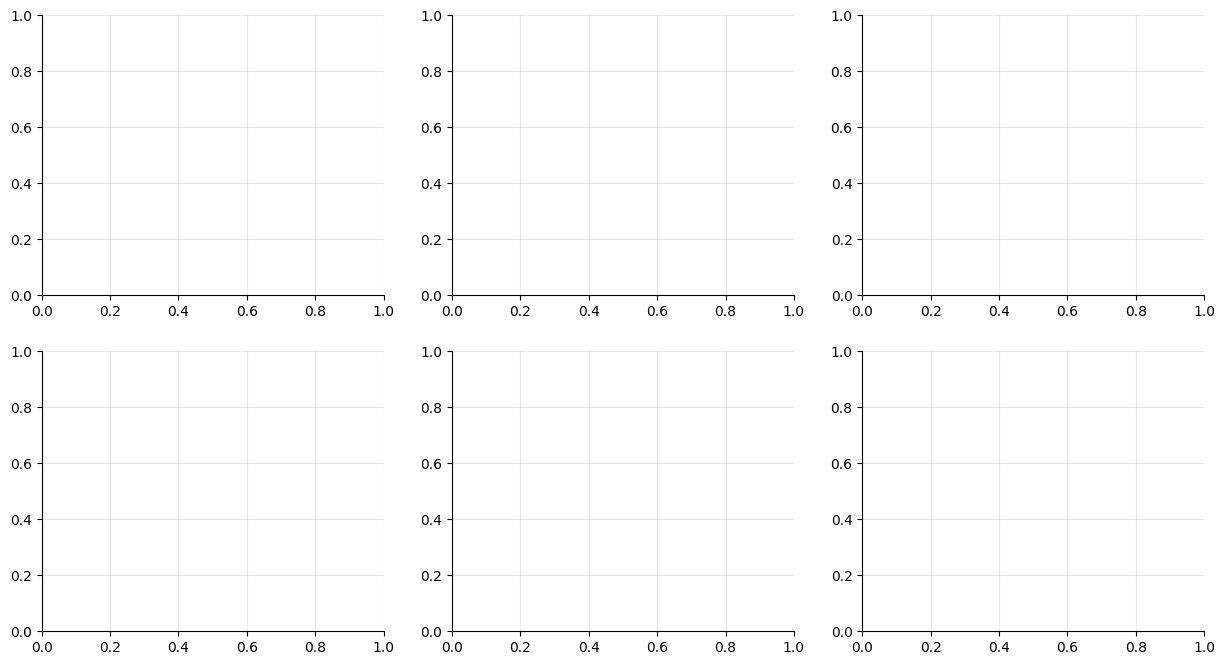

In [5]:
KEY_FEATURES = [
    ('temp_mean_15d',          '°C',    'Température moyenne'),
    ('rain_sum_15d',           'mm',    'Pluie cumulée'),
    ('rain_days_15d',          'jours', 'Jours de pluie'),
    ('humidity_mean_15d',      '%',     'Humidité moyenne'),
    ('vpd_max_15d',            'kPa',   'VPD max'),
    ('soil_moisture_mean_15d', '',      'Humidité du sol (moy.)'),
]
key_available = [(c, u, t) for c, u, t in KEY_FEATURES if c in df_bio.columns]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, (col, unit, title) in enumerate(key_available):
    ax = axes[i]
    
    # Données par bio
    data_by_bio = [df_bio[df_bio['nom_bioagresseur'] == bio][col].dropna().values
                   for bio in TOP_BIO]
    
    # Boxplot
    bp = ax.boxplot(data_by_bio, labels=TOP_BIO, widths=0.55,
                    patch_artist=True, medianprops=dict(color='white', linewidth=2))
    for patch, color in zip(bp['boxes'], BIO_PALETTE[:len(TOP_BIO)]):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    
    # Scatter des points individuels (jitter horizontal)
    for j, (bio, color) in enumerate(zip(TOP_BIO, BIO_PALETTE[:len(TOP_BIO)])):
        vals = df_bio[df_bio['nom_bioagresseur'] == bio][col].dropna().values
        x_jitter = np.random.normal(j + 1, 0.05, size=len(vals))
        ax.scatter(x_jitter, vals, color=color, s=40,
                   edgecolor='white', linewidth=1, zorder=10, alpha=0.95)
    
    # Médiane globale (toute la population 31)
    median_all = df_features[col].median()
    ax.axhline(median_all, color=C_NEUTRAL, linestyle='--', linewidth=1, alpha=0.6,
               label=f'médiane globale ({median_all:.1f})')
    
    ax.set_title(title, fontsize=10, loc='left', fontweight='bold')
    ax.set_ylabel(unit, fontsize=9)
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)
    ax.legend(fontsize=7, loc='upper right', framealpha=0.9)
    ax.grid(alpha=0.3)

plt.suptitle('Distribution des features clés par bioagresseur observé\n'
             f'(bioagresseurs avec ≥ 2 cas, n={len(df_bio)} bulletins)',
             fontsize=11, fontweight='bold', x=0.04, ha='left', y=1.01)
plt.tight_layout()
plt.show()

### Lecture des boxplots

Plusieurs choses à observer ici :

- **Cohérence agronomique** : un bioagresseur favorisé par l'humidité (mildiou, septoriose) devrait avoir des valeurs hautes en `rain_sum_15d` et `humidity_mean_15d`, basses en `vpd_max_15d`.
- **Variance intra-pathologie** : si tous les points d'une même pathologie sont serrés, on a un signal météo cohérent. Étalés, on a soit une vraie diversité de contextes, soit du bruit.
- **Échantillon trop petit** : avec 2-6 cas par pathologie, il faut considérer ces patterns comme des **indications**, pas des conclusions.

## 3. Heatmap features × bioagresseurs (matplotlib)

Vue compacte : pour chaque pathologie, **valeur moyenne de chaque feature**, normalisée sur l'ensemble des 31 bulletins. Rouge = haut par rapport au pool, bleu = bas.

/tmp/ipykernel_89530/936664663.py:10: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im = ax.imshow(means_norm.values, aspect='auto', cmap='RdYlBu_r',


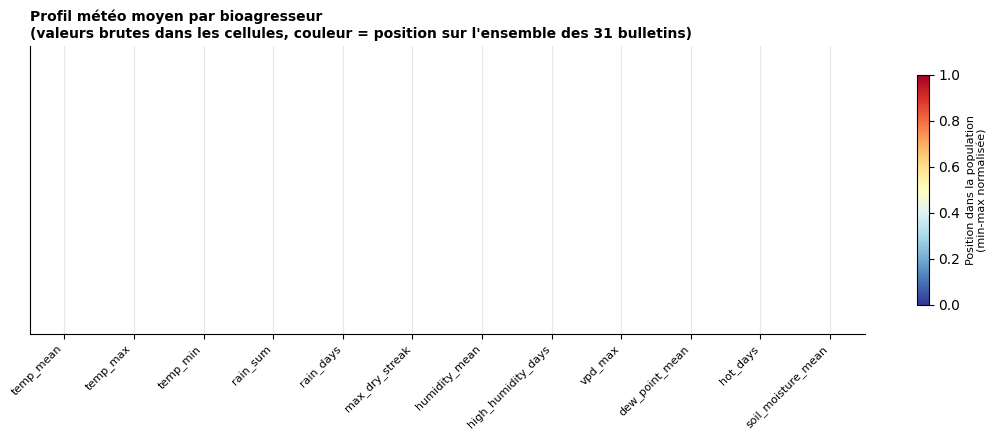

In [6]:
# Tableau moyenne par bioagresseur
means_by_bio = df_bio.groupby('nom_bioagresseur', observed=True)[FEATURE_COLS].mean()

# Normalisation min-max sur l'ensemble des 31 (pas seulement TOP_BIO)
scale_min = df_features[FEATURE_COLS].min()
scale_max = df_features[FEATURE_COLS].max()
means_norm = (means_by_bio - scale_min) / (scale_max - scale_min)

fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(means_norm.values, aspect='auto', cmap='RdYlBu_r',
                interpolation='nearest', vmin=0, vmax=1)

ax.set_xticks(range(len(FEATURE_COLS)))
ax.set_xticklabels([c.replace('_15d', '') for c in FEATURE_COLS],
                   rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(TOP_BIO)))
ax.set_yticklabels([f'{bio} (n={bio_counts[bio]})' for bio in TOP_BIO], fontsize=9)

# Annoter chaque cellule avec la valeur brute
for i, bio in enumerate(TOP_BIO):
    for j, col in enumerate(FEATURE_COLS):
        val = means_by_bio.iloc[i, j]
        norm = means_norm.iloc[i, j]
        text_color = 'white' if (norm < 0.25 or norm > 0.75) else 'black'
        ax.text(j, i, f'{val:.1f}', ha='center', va='center',
                fontsize=7, color=text_color)

cbar = plt.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label('Position dans la population\n(min-max normalisée)', fontsize=8)

ax.set_title('Profil météo moyen par bioagresseur\n'
             '(valeurs brutes dans les cellules, couleur = position sur l\'ensemble des 31 bulletins)',
             loc='left', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

## 4. Profils radar par pathologie (plotly interactif)

Comparaison interactive : chaque polygone = la moyenne d'une pathologie sur 6 features clés, normalisée sur l'ensemble des 31 bulletins. Plus le polygone est étalé sur un axe, plus la pathologie est associée à des valeurs hautes de cette feature.

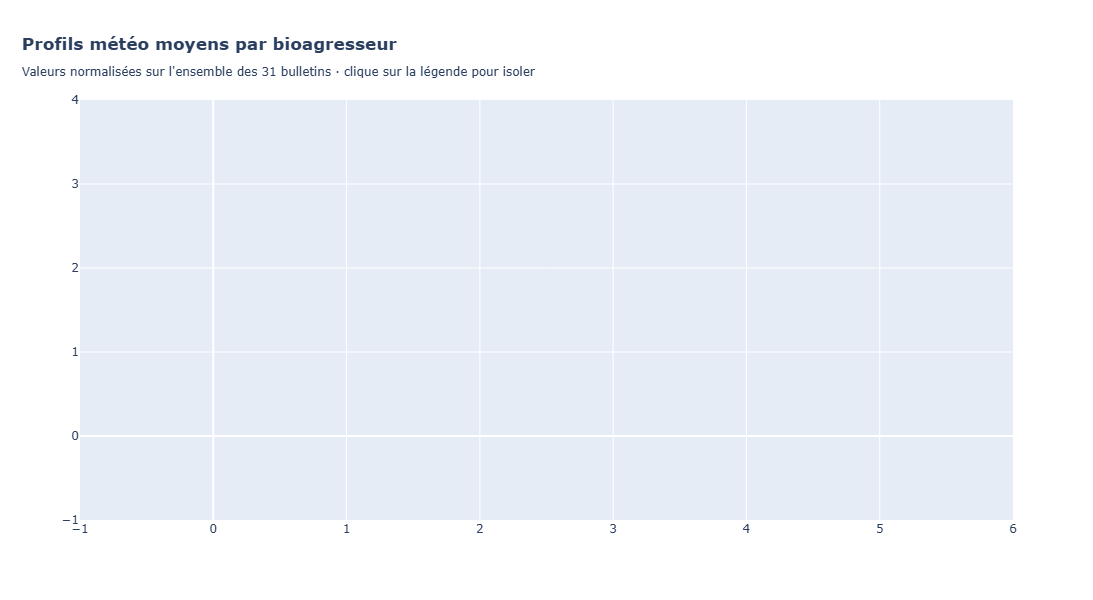

In [7]:
radar_features = ['rain_sum_15d', 'humidity_mean_15d', 'vpd_max_15d',
                  'temp_mean_15d', 'soil_moisture_mean_15d', 'max_dry_streak_15d']
radar_features = [f for f in radar_features if f in FEATURE_COLS]
radar_labels = [f.replace('_15d', '') for f in radar_features]

fig = go.Figure()

for bio, color in zip(TOP_BIO, BIO_PALETTE[:len(TOP_BIO)]):
    means_bio = df_bio[df_bio['nom_bioagresseur'] == bio][radar_features].mean()
    norm_bio = [(means_bio[f] - scale_min[f]) / (scale_max[f] - scale_min[f])
                if scale_max[f] > scale_min[f] else 0.5
                for f in radar_features]
    raw_vals = means_bio.tolist()
    
    hover = [f'{lbl}<br>Moyenne: {raw:.2f}<br>Normalisée: {norm:.2f}'
             for lbl, raw, norm in zip(radar_labels, raw_vals, norm_bio)]
    
    fig.add_trace(go.Scatterpolar(
        r=norm_bio + [norm_bio[0]],
        theta=radar_labels + [radar_labels[0]],
        fill='toself',
        fillcolor=color,
        opacity=0.25,
        line=dict(color=color, width=2.5),
        name=f'{bio} (n={bio_counts[bio]})',
        text=hover + [hover[0]],
        hoverinfo='text+name',
    ))

fig.update_layout(
    title=dict(
        text='<b>Profils météo moyens par bioagresseur</b><br>'
             '<sub>Valeurs normalisées sur l\'ensemble des 31 bulletins · clique sur la légende pour isoler</sub>',
        x=0.02, xanchor='left'
    ),
    polar=dict(
        radialaxis=dict(visible=True, range=[0, 1], tickfont=dict(size=9)),
        angularaxis=dict(tickfont=dict(size=10)),
    ),
    height=600,
    legend=dict(font=dict(size=10)),
)
fig.show()

## 5. Matrice de corrélation des features (matplotlib)

Spearman pour rester robuste aux distributions non gaussiennes (peu d'observations, valeurs entières comme `rain_days_15d`).

In [ ]:
corr = df_features[FEATURE_COLS].corr(method='spearman')

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1, aspect='equal')

labels_clean = [c.replace('_15d', '') for c in FEATURE_COLS]
ax.set_xticks(range(len(labels_clean)))
ax.set_yticks(range(len(labels_clean)))
ax.set_xticklabels(labels_clean, rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(labels_clean, fontsize=9)

# Annoter chaque cellule
for i in range(len(labels_clean)):
    for j in range(len(labels_clean)):
        val = corr.iloc[i, j]
        color = 'white' if abs(val) > 0.55 else 'black'
        weight = 'bold' if abs(val) > 0.7 else 'normal'
        ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                fontsize=7, color=color, fontweight=weight)

cbar = plt.colorbar(im, ax=ax, shrink=0.7)
cbar.set_label('Corrélation de Spearman', fontsize=9)

ax.set_title('Matrice de corrélation des 12 features météo\n'
             '(Spearman, sur les 31 bulletins avec features)',
             loc='left', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Top des corrélations fortes (|r| > 0.7), hors diagonale
corr_long = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().reset_index()
corr_long.columns = ['feature_a', 'feature_b', 'spearman_r']
corr_long['abs_r'] = corr_long['spearman_r'].abs()

strong_pairs = corr_long[corr_long['abs_r'] > 0.7].sort_values('abs_r', ascending=False)

print('Corrélations |Spearman| > 0.7 :\n')
for _, row in strong_pairs.iterrows():
    sign = '+' if row['spearman_r'] > 0 else '−'
    print(f'  {sign} {row["spearman_r"]:+.2f}   '
          f'{row["feature_a"].replace("_15d",""):25s} '
          f'↔  {row["feature_b"].replace("_15d","")}')

print(f'\nTotal de paires fortement corrélées : {len(strong_pairs)} sur {len(corr_long)}')

### Lecture de la matrice

- **Corrélations attendues** (à valider visuellement) : `rain_sum` ↔ `rain_days`, `humidity_mean` ↔ `dew_point_mean`, `vpd_max` ↔ `humidity_mean` (négative).
- **Si une paire est très corrélée** (|r| > 0.85), garder les **deux features** apporte peu d'information supplémentaire. Pour les règles agronomiques, ce n'est pas grave (chaque feature est interprétée individuellement). Pour un futur modèle ML, on choisirait l'une des deux.
- **Cas particulier** : `temp_max`, `temp_mean`, `temp_min` sont presque toujours très corrélées entre elles.

## 6. PCA exploratoire (plotly interactif)

Projeter les 31 bulletins en 2D pour voir si les bioagresseurs forment des clusters distincts dans l'espace des features.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Préparer X (sans imputation, on garde uniquement les lignes complètes)
X = df_features[FEATURE_COLS].dropna()
idx = X.index

X_scaled = StandardScaler().fit_transform(X.values)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# DataFrame pour plotly
df_pca = df_features.loc[idx].copy()
df_pca['PC1'] = X_pca[:, 0]
df_pca['PC2'] = X_pca[:, 1]
df_pca['bio_for_color'] = df_pca['nom_bioagresseur'].fillna('Non renseigné')
df_pca['hover'] = df_pca.apply(
    lambda r: f"#{int(r['bulletin_id'])} · {r['city'] or '?'}<br>"
              f"{r['nom_espece'] or '?'}<br>"
              f"Diagnostic: {r['bio_for_color']}<br>"
              f"Date: {r['datetime_observation'].strftime('%Y-%m-%d')}<br>"
              f"Pluie 15j: {r['rain_sum_15d']:.0f} mm · T moy: {r['temp_mean_15d']:.1f}°C",
    axis=1
)

fig = px.scatter(
    df_pca, x='PC1', y='PC2',
    color='bio_for_color',
    hover_name='hover',
    hover_data={'PC1': ':.2f', 'PC2': ':.2f',
                'bio_for_color': False},
    color_discrete_sequence=BIO_PALETTE + ['#cccccc'],
)
fig.update_traces(marker=dict(size=12, line=dict(color='white', width=1.5)))

fig.update_layout(
    title=dict(
        text=f'<b>PCA exploratoire — 31 bulletins projetés en 2D</b><br>'
             f'<sub>PC1: {100*pca.explained_variance_ratio_[0]:.0f}% · '
             f'PC2: {100*pca.explained_variance_ratio_[1]:.0f}% · '
             f'Total: {100*sum(pca.explained_variance_ratio_):.0f}% de la variance</sub>',
        x=0.02, xanchor='left'
    ),
    xaxis_title=f'PC1 ({100*pca.explained_variance_ratio_[0]:.0f}%)',
    yaxis_title=f'PC2 ({100*pca.explained_variance_ratio_[1]:.0f}%)',
    height=550,
    plot_bgcolor='white',
    legend=dict(font=dict(size=10)),
)
fig.update_xaxes(showgrid=True, gridcolor='#eee', zeroline=True, zerolinecolor='#ccc')
fig.update_yaxes(showgrid=True, gridcolor='#eee', zeroline=True, zerolinecolor='#ccc')
fig.show()

In [ ]:
# Composition des axes principaux : quelles features dominent PC1 et PC2 ?
loadings = pd.DataFrame(pca.components_.T,
                        index=FEATURE_COLS,
                        columns=['PC1', 'PC2'])

fig, ax = plt.subplots(figsize=(8, 6))
x_loadings = loadings['PC1'].values
y_loadings = loadings['PC2'].values

for f, x, y in zip(FEATURE_COLS, x_loadings, y_loadings):
    ax.arrow(0, 0, x, y, head_width=0.02, head_length=0.025,
             fc=C_PRIMARY, ec=C_PRIMARY, alpha=0.7, length_includes_head=True)
    ax.annotate(f.replace('_15d', ''), (x*1.12, y*1.12),
                fontsize=8, ha='center', va='center')

# Cercle unitaire
theta = np.linspace(0, 2*np.pi, 100)
ax.plot(np.cos(theta), np.sin(theta), color=C_NEUTRAL, linewidth=0.8, linestyle='--', alpha=0.5)

ax.axhline(0, color=C_NEUTRAL, linewidth=0.5, alpha=0.5)
ax.axvline(0, color=C_NEUTRAL, linewidth=0.5, alpha=0.5)
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_xlabel(f'PC1 ({100*pca.explained_variance_ratio_[0]:.0f}%)')
ax.set_ylabel(f'PC2 ({100*pca.explained_variance_ratio_[1]:.0f}%)')
ax.set_title('Cercle des corrélations — contribution des features aux axes principaux',
             loc='left', fontweight='bold', fontsize=10)
ax.set_aspect('equal')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Lecture du cercle des corrélations

- **Features pointant dans la même direction** : fortement corrélées positivement
- **Features opposées (à 180°)** : corrélées négativement
- **Features orthogonales (à 90°)** : non corrélées, apportent une information indépendante
- **Features près du centre** : faiblement représentées sur ces deux axes (information ailleurs)

## 7. Sélection des features non-redondantes

À partir des corrélations, on peut proposer un **sous-ensemble réduit** de features qui capture l'essentiel de l'information. C'est utile pour :
- alléger le vecteur transmis au module de fusion ;
- éviter de pondérer plusieurs fois la même information (eg `temp_mean` ≈ `temp_max` ≈ `temp_min`).

In [ ]:
# Stratégie : pour chaque groupe de features fortement corrélées (|r| > 0.85),
# garder uniquement la plus représentative (celle de plus haute variance,
# = celle qui sépare le mieux les bulletins).

STRONG_THRESHOLD = 0.85

# Composantes connexes du graphe de corrélation
from itertools import combinations

kept = []
dropped = []
remaining = list(FEATURE_COLS)
variances = df_features[FEATURE_COLS].var()

# On parcourt les features par variance décroissante, on garde, et on drop
# tout ce qui est très corrélé à ce qu'on a déjà gardé
for f in variances.sort_values(ascending=False).index:
    if f not in remaining:
        continue
    kept.append(f)
    remaining.remove(f)
    # Drop les features très corrélées à f
    for other in list(remaining):
        if abs(corr.loc[f, other]) > STRONG_THRESHOLD:
            dropped.append((other, f, corr.loc[f, other]))
            remaining.remove(other)

print(f'Sous-ensemble proposé ({len(kept)} features non-redondantes à |r| ≤ {STRONG_THRESHOLD}) :')
for f in kept:
    print(f'  ✓ {f}')

print(f'\nFeatures écartées par redondance ({len(dropped)}) :')
for other, ref, r in dropped:
    print(f'  − {other:30s} (corrélée à {ref}, r={r:+.2f})')

## 8. Synthèse pour le rapport

In [ ]:
print('=' * 70)
print('SYNTHÈSE — Analyse approfondie phase 2')
print('=' * 70)
print()
print(f'Échantillon analysé : {len(df_features)} bulletins avec features météo')
print()
print(f'Bioagresseurs renseignés avec ≥ 2 cas (n={len(df_bio)} bulletins) :')
for bio in TOP_BIO:
    print(f'  - {bio:30s} ({bio_counts[bio]} cas)')
print()
print('Profil météo dominant du corpus :')
print(f'  Température moyenne : {df_features["temp_mean_15d"].mean():.1f} °C '
      f'(±{df_features["temp_mean_15d"].std():.1f})')
print(f'  Pluie cumulée moy.  : {df_features["rain_sum_15d"].mean():.1f} mm '
      f'(±{df_features["rain_sum_15d"].std():.1f})')
print(f'  Humidité moyenne    : {df_features["humidity_mean_15d"].mean():.1f} % '
      f'(±{df_features["humidity_mean_15d"].std():.1f})')
print(f'  VPD max moyen       : {df_features["vpd_max_15d"].mean():.2f} kPa '
      f'(±{df_features["vpd_max_15d"].std():.2f})')
print()
print('Corrélations entre features :')
print(f'  Paires |r| > 0.85   : {len(corr_long[corr_long["abs_r"] > 0.85])}')
print(f'  Paires |r| > 0.70   : {len(strong_pairs)}')
print()
print(f'Variance expliquée par PCA :')
print(f'  PC1                 : {100*pca.explained_variance_ratio_[0]:.0f}%')
print(f'  PC1 + PC2           : {100*sum(pca.explained_variance_ratio_):.0f}%')
print()
print(f'Sous-ensemble non-redondant proposé : {len(kept)} features sur {len(FEATURE_COLS)}')

---

## Conclusions pour le rapport

**Profondeur agronomique**
- Les boxplots et radars permettent une lecture qualitative des profils météo associés à chaque pathologie observée, à interpréter avec prudence vu le faible n par classe.
- Cette analyse est **descriptive** : elle ne valide pas les règles agronomiques, elle décrit les contextes dans lesquels les observations ont été faites.

**Structure interne des features**
- La matrice de corrélation identifie les groupes de features qui mesurent essentiellement la même chose.
- Le sous-ensemble non-redondant proposé peut servir de **vecteur compact** pour le module de fusion, sans perte d'information substantielle.
- La PCA confirme que la variance est concentrée sur les deux premiers axes — utile pour visualiser et clusteriser à l'avenir.

**Limite générale**
- n=31 reste un échantillon modeste. Les analyses gagneraient beaucoup à être refaites quand le corpus aura cru d'un ordre de grandeur (cible 300+ bulletins phase2_ready).